© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **Gradients and Regression (SOLUTION)**

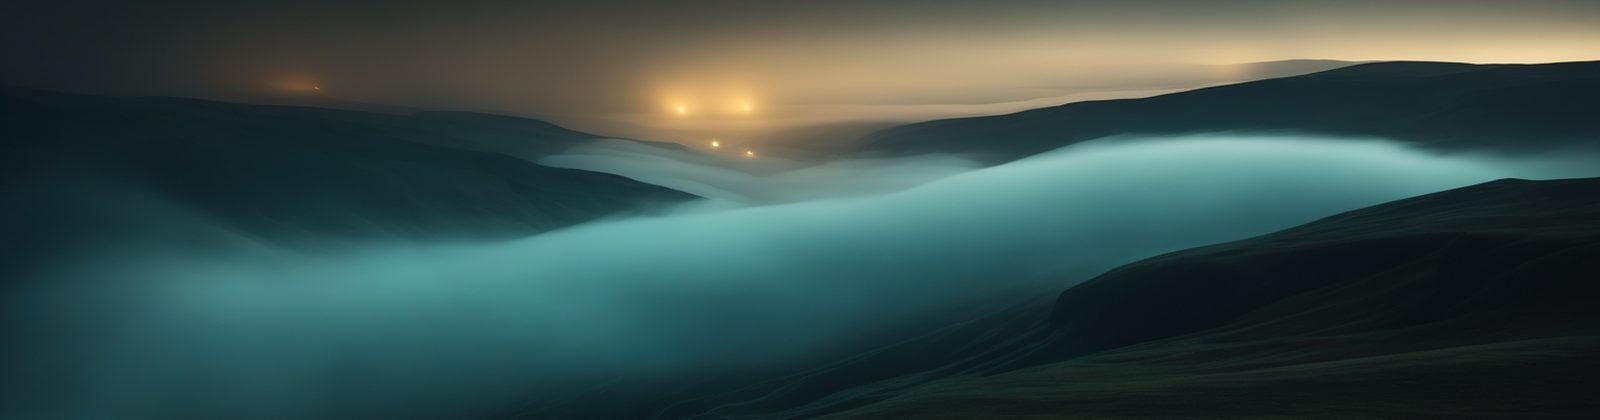

## **Task overview**

Part a computes derivatives with autograd and runs gradient descent by hand. Part b fits a straight line and then a small MLP to 200 points on a curve. Part c predicts `spend` on the customer register with the same two models and compares them with a baseline.

| Part | Task | Points |
|---|---|---:|
| a | Derivatives from `backward()` and a gradient descent | 30 |
| b | A line and an MLP fitted to a curve | 35 |
| c | `spend` predicted on the register | 35 |

Every answer is an integer. Where a row is not a count, it is reported **times 1000, or in units of `spend`, rounded to the nearest whole number**, as stated for that row below. A part is scored `points * (correct rows / total rows)`. A float32 and a float64 computation give the same rounded answers.



## **Task specification**

`register.csv` has 9000 rows and a header. `age`, `income`, `tenure_months` and `score` are numeric, and `age`, `income` and `score` have missing values, written as empty fields. `region`, `plan` and `channel` are text. `churn` is 0 or 1, `spend` is an amount, and `split` is `train` or `test`; these three have no missing values. `queries.json` holds three points for part a, `curve.csv` the 200 points `x, y` of part b, and `init.json` the starting parameters of the two MLPs, each in the format `state_dict()` returns.

**Part a, 21 rows.**

- rows `0..11`: for each of the three points `[a, b, c, d]` in `queries.json`, in order, the partial derivatives of `f(a, b, c, d) = (a * b + c) ** 2 / d` with respect to `a`, `b`, `c` and `d`, in that order, **times 1000**. Rows `0..3` belong to the first point.
- rows `12..20`: gradient descent on one feature. `x` is `tenure_months` standardised: minus its mean, divided by its standard deviation. `y` is `churn` as a float. The prediction is `w * x + b` and the loss is the mean of `(prediction - y) ** 2` over all 9000 rows. `w` and `b` start at `0`, and each of `50` steps computes the loss, calls `backward()`, and subtracts `0.1` times each gradient from its parameter. Rows `12..18` are the loss **before** the update at steps `0, 3, 6, 9, 12, 15, 20`, and rows `19` and `20` are `w` and `b` after the 50 updates, all **times 1000**.

**Part b, 10 rows.** Both models are trained on all 200 points of `curve.csv`, with `x` as a tensor of shape `(200, 1)` and `y` as a tensor of shape `(200, 1)`. The loss is `nn.MSELoss()`, and each step of full-batch gradient descent computes the loss, then calls `zero_grad()`, `backward()` and `step()` of a `torch.optim.SGD` optimizer.

- rows `0..2`: a straight line, `nn.Linear(1, 1)` with its weight and bias set to `0`, trained for `100` steps at learning rate `0.1`. Its weight, its bias, and its loss on the 200 points after the last step, all **times 1000**.
- rows `3..9`: an MLP, `nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1))`, started from the parameters under `"curve"` in `init.json` and trained for `3000` steps at learning rate `0.05`. Row `3` is its loss before the first update, row `4` its loss after the last step, and rows `5..9` its predictions at `x = -2, -1, 0, 1, 2`, all **times 1000**.

**Part c, 7 rows.** `spend` is predicted from `tenure_months`, `score` and `income`, in that order, using only the rows where all three are present. The rows with `split == "train"` are the training rows and those with `split == "test"` the test rows. Each feature is standardised with the mean and the standard deviation of the **training rows**, the standard deviation that divides by the count. The target is `spend / 1000`, as a tensor of shape `(n, 1)`. Both models are trained on the training rows with `nn.MSELoss()` and full-batch `torch.optim.SGD`, as in part b. An RMSE is `sqrt(mean((prediction - target) ** 2))` over the test rows, reported **in units of `spend`**: the RMSE of the target in thousands, times 1000.

- row `0`: the RMSE of predicting the mean `spend` of the training rows for every test row.
- rows `1..4`: a straight line, `nn.Linear(3, 1)` with its weights and bias set to `0`, trained for `200` steps at learning rate `0.1`. Its weights for `tenure_months`, `score` and `income`, then its bias, all **times 1000**.
- row `5`: the RMSE of that line.
- row `6`: the RMSE of an MLP, `nn.Sequential(nn.Linear(3, 16), nn.ReLU(), nn.Linear(16, 1))`, started from the parameters under `"register"` in `init.json` and trained for `1000` steps at learning rate `0.1`.

## **Useful Links**

- [`torch.Tensor`](https://docs.pytorch.org/docs/stable/tensors.html)
- [A Gentle Introduction to `torch.autograd`](https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html)
- [`torch.nn.Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)
- [`torch.nn.Sequential`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html)
- [`torch.nn.MSELoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html)
- [`torch.optim.SGD`](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html)
- [`Module.load_state_dict`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.load_state_dict)

## **Setup and data**

In [ ]:
# ══════════════════════════════════════════════════════════
# Setup. DO NOT MODIFY.
# ══════════════════════════════════════════════════════════
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

def write_submission(filename, rows):
    """Write [(id, target), ...] as a DOCK-ready CSV."""
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "target"])
        for row_id, target in rows:
            writer.writerow([int(row_id), int(target)])
    print(f"wrote {filename}: {len(rows)} rows")

# Download register.csv, queries.json, curve.csv and init.json from the exercise page on
# DOCK and put them next to this notebook (in Colab: drag them into the file browser).
def _find(name):
    here = Path(name)
    return here if here.exists() else Path("data") / name

with open(_find("register.csv"), newline="", encoding="utf-8") as f:
    records = list(csv.DictReader(f))
points = json.loads(_find("queries.json").read_text(encoding="utf-8"))["points"]
init = json.loads(_find("init.json").read_text(encoding="utf-8"))
with open(_find("curve.csv"), newline="", encoding="utf-8") as f:
    curve = list(csv.DictReader(f))

def column(name):
    """One column as a float array, with missing values as np.nan."""
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

income, tenure, score = column("income"), column("tenure_months"), column("score")
spend = column("spend")
churn = np.array([int(r["churn"]) for r in records])
split = np.array([r["split"] for r in records])
curve_x = np.array([float(r["x"]) for r in curve])
curve_y = np.array([float(r["y"]) for r in curve])

print(f"{len(records)} rows, {int((split == 'train').sum())} train and "
      f"{int((split == 'test').sum())} test")
print(f"{len(curve_x)} curve points, x from {curve_x.min()} to {curve_x.max()}")
print("points for part a:", points)
print("init.json:", {k: list(v) for k, v in init.items()})

## **A first look**

In [ ]:
# ── Plotting helpers (no need to modify) ──

def show_points(x, y, xlabel, ylabel):
    k = ~np.isnan(x) & ~np.isnan(y)
    plt.figure(figsize=(5, 3.4))
    plt.scatter(x[k], y[k], s=6, alpha=0.4, linewidths=0)
    plt.xlabel(xlabel); plt.ylabel(ylabel)
    plt.tight_layout(); plt.show()

def show_fit(x, y, *models):
    """The points and the prediction of each model over the range of x."""
    grid = torch.linspace(float(x.min()), float(x.max()), 300).reshape(-1, 1)
    plt.figure(figsize=(6, 3.6))
    plt.scatter(x, y, s=8, alpha=0.5, linewidths=0, color="grey")
    for m in models:
        plt.plot(grid.reshape(-1), m(grid.to(next(m.parameters()).dtype)).detach().reshape(-1),
                 lw=2, label=type(m).__name__)
    plt.legend(); plt.xlabel("x"); plt.ylabel("y")
    plt.tight_layout(); plt.show()

show_points(curve_x, curve_y, "x", "y")
show_points(tenure, spend, "tenure_months", "spend")

---
## **Part a: Autograd and gradient descent (30 points)**

For the derivatives, each of `a`, `b`, `c` and `d` is a tensor created with `requires_grad=True`; after `backward()` on `f`, each one's `.grad` holds the derivative of `f` with respect to it. In the gradient descent, `backward()` adds into `.grad`, so both gradients are reset after every update, and the update itself runs inside `torch.no_grad()`.

Submission: `part1_submission.csv`, 21 rows, uploaded to part a.

In [ ]:
def f(a, b, c, d):
    return (a * b + c) ** 2 / d

derivs = []
for p in points:
    leaves = [torch.tensor(v, requires_grad=True) for v in p]   # float32 scalars
    f(*leaves).backward()
    derivs += [int(round(t.grad.item() * 1000)) for t in leaves]

x = torch.tensor((tenure - tenure.mean()) / tenure.std(), dtype=torch.float32)
y = torch.tensor(churn, dtype=torch.float32)
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

losses = []
for step in range(50):
    loss = ((w * x + b - y) ** 2).mean()
    losses.append(loss.item())
    loss.backward()
    with torch.no_grad():
        w -= 0.1 * w.grad
        b -= 0.1 * b.grad
    w.grad.zero_()
    b.grad.zero_()

record = [losses[s] for s in (0, 3, 6, 9, 12, 15, 20)] + [w.item(), b.item()]
part1 = list(enumerate(derivs + [int(round(v * 1000)) for v in record]))

write_submission("part1_submission.csv", part1)
part1

---
## **Part b: A line and an MLP on a curve (35 points)**

`nn.MSELoss` compares its two arguments element by element, so the prediction, of shape `(200, 1)`, and the target have to have the same shape; a target of shape `(200,)` is broadcast to `(200, 200)` with only a warning. `load_state_dict` takes a dictionary of tensors, so the lists in `init.json` are converted with `torch.tensor` first. `show_fit` draws both models over the points.

Submission: `part2_submission.csv`, 10 rows, uploaded to part b.

In [ ]:
X = torch.tensor(curve_x, dtype=torch.float32).reshape(-1, 1)     # (200, 1)
Y = torch.tensor(curve_y, dtype=torch.float32).reshape(-1, 1)     # (200, 1), the shape of the prediction
loss_fn = nn.MSELoss()

def fit(model, X, Y, lr, steps):
    """Full-batch gradient descent; returns the loss before the first update."""
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    first = None
    for step in range(steps):
        loss = loss_fn(model(X), Y)
        if step == 0:
            first = loss.item()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return first

line = nn.Linear(1, 1)
with torch.no_grad():
    line.weight.zero_()
    line.bias.zero_()
fit(line, X, Y, 0.1, 100)

mlp = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1))
mlp.load_state_dict({k: torch.tensor(v) for k, v in init["curve"].items()})
first = fit(mlp, X, Y, 0.05, 3000)

with torch.no_grad():
    line_loss = loss_fn(line(X), Y).item()
    mlp_loss = loss_fn(mlp(X), Y).item()
    pred = mlp(torch.tensor([[-2.0], [-1.0], [0.0], [1.0], [2.0]])).reshape(-1).tolist()

values = [line.weight.item(), line.bias.item(), line_loss, first, mlp_loss] + pred
part2 = list(enumerate(int(round(v * 1000)) for v in values))

show_fit(curve_x, curve_y, line, mlp)
write_submission("part2_submission.csv", part2)
part2

---
## **Part c: Spend on the register (35 points)**

The mean and the standard deviation come from the training rows only, and the test rows are scaled with those same two numbers. `income` is in tens of thousands and `score` below 100, so without the standardisation one learning rate cannot suit both weights.

Submission: `part3_submission.csv`, 7 rows, uploaded to part c.

In [ ]:
F = np.stack([tenure, score, income], axis=1)                     # (9000, 3)
present = ~np.isnan(F).any(axis=1)
train, test = present & (split == "train"), present & (split == "test")
mean, std = F[train].mean(axis=0), F[train].std(axis=0)            # numpy's std divides by n

Xtr = torch.tensor((F[train] - mean) / std, dtype=torch.float32)
Xte = torch.tensor((F[test] - mean) / std, dtype=torch.float32)
ytr = torch.tensor(spend[train] / 1000, dtype=torch.float32).reshape(-1, 1)
yte = torch.tensor(spend[test] / 1000, dtype=torch.float32).reshape(-1, 1)

def rmse(pred, target):
    return ((pred - target) ** 2).mean().sqrt().item() * 1000       # back to units of spend

baseline = rmse(torch.full_like(yte, ytr.mean().item()), yte)

line = nn.Linear(3, 1)
with torch.no_grad():
    line.weight.zero_()
    line.bias.zero_()
fit(line, Xtr, ytr, 0.1, 200)                                       # fit() from part b

mlp = nn.Sequential(nn.Linear(3, 16), nn.ReLU(), nn.Linear(16, 1))
mlp.load_state_dict({k: torch.tensor(v) for k, v in init["register"].items()})
fit(mlp, Xtr, ytr, 0.1, 1000)

with torch.no_grad():
    r_line, r_mlp = rmse(line(Xte), yte), rmse(mlp(Xte), yte)

weights = [v * 1000 for v in line.weight.reshape(-1).tolist()] + [line.bias.item() * 1000]
part3 = list(enumerate(int(round(v)) for v in [baseline] + weights + [r_line, r_mlp]))

print(f"RMSE: mean {baseline:.1f}, line {r_line:.1f}, MLP {r_mlp:.1f}")
write_submission("part3_submission.csv", part3)
part3

In [ ]:
# ── Evaluator reproduction: mirrors grader/_common.py exactly ──
def exact_match_points(rows, solution_csv, max_score):
    with open(solution_csv, newline="", encoding="utf-8") as f:
        gt = {int(r["id"]): int(r["target"]) for r in csv.DictReader(f)}
    submitted = {int(i): int(t) for i, t in rows}
    assert set(submitted) == set(gt), "id set mismatch"
    correct = sum(1 for k in gt if submitted[k] == gt[k])
    return int(round(correct / len(gt) * max_score))


total = 0
for n, rows, mx in ((1, part1, 30), (2, part2, 35), (3, part3, 35)):
    pts = exact_match_points(rows, f"grader/{n}_solution.csv", mx)
    total += pts
    print(f"part {n}: {pts}/{mx}")
print(f"total:  {total}/100")

---
## **Submission**

Upload each CSV to its own part on DOCK.

